# Práctica 1: Perceptrón multicapa.

Tu jefe pidió a RH que recolectara datos de desempeño de tus compañeros, los resultados se almacenaron en un csv. El punto critico de estos datos es la satisfacción del empleado, entonces ¿Podremos estimar la satisfacción de los empleados con los datos recabados?.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models
from IPython.display import display, Markdown

tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()
tf.config.threading.set_intra_op_parallelism_threads(2)
tf.config.threading.set_inter_op_parallelism_threads(2)
print('TensorFlow:', tf.__version__)
df = pd.read_csv('Extended_Employee_Performance_and_Productivity_Data.csv')
df.info()

TensorFlow: 2.21.0
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 non-null  int64

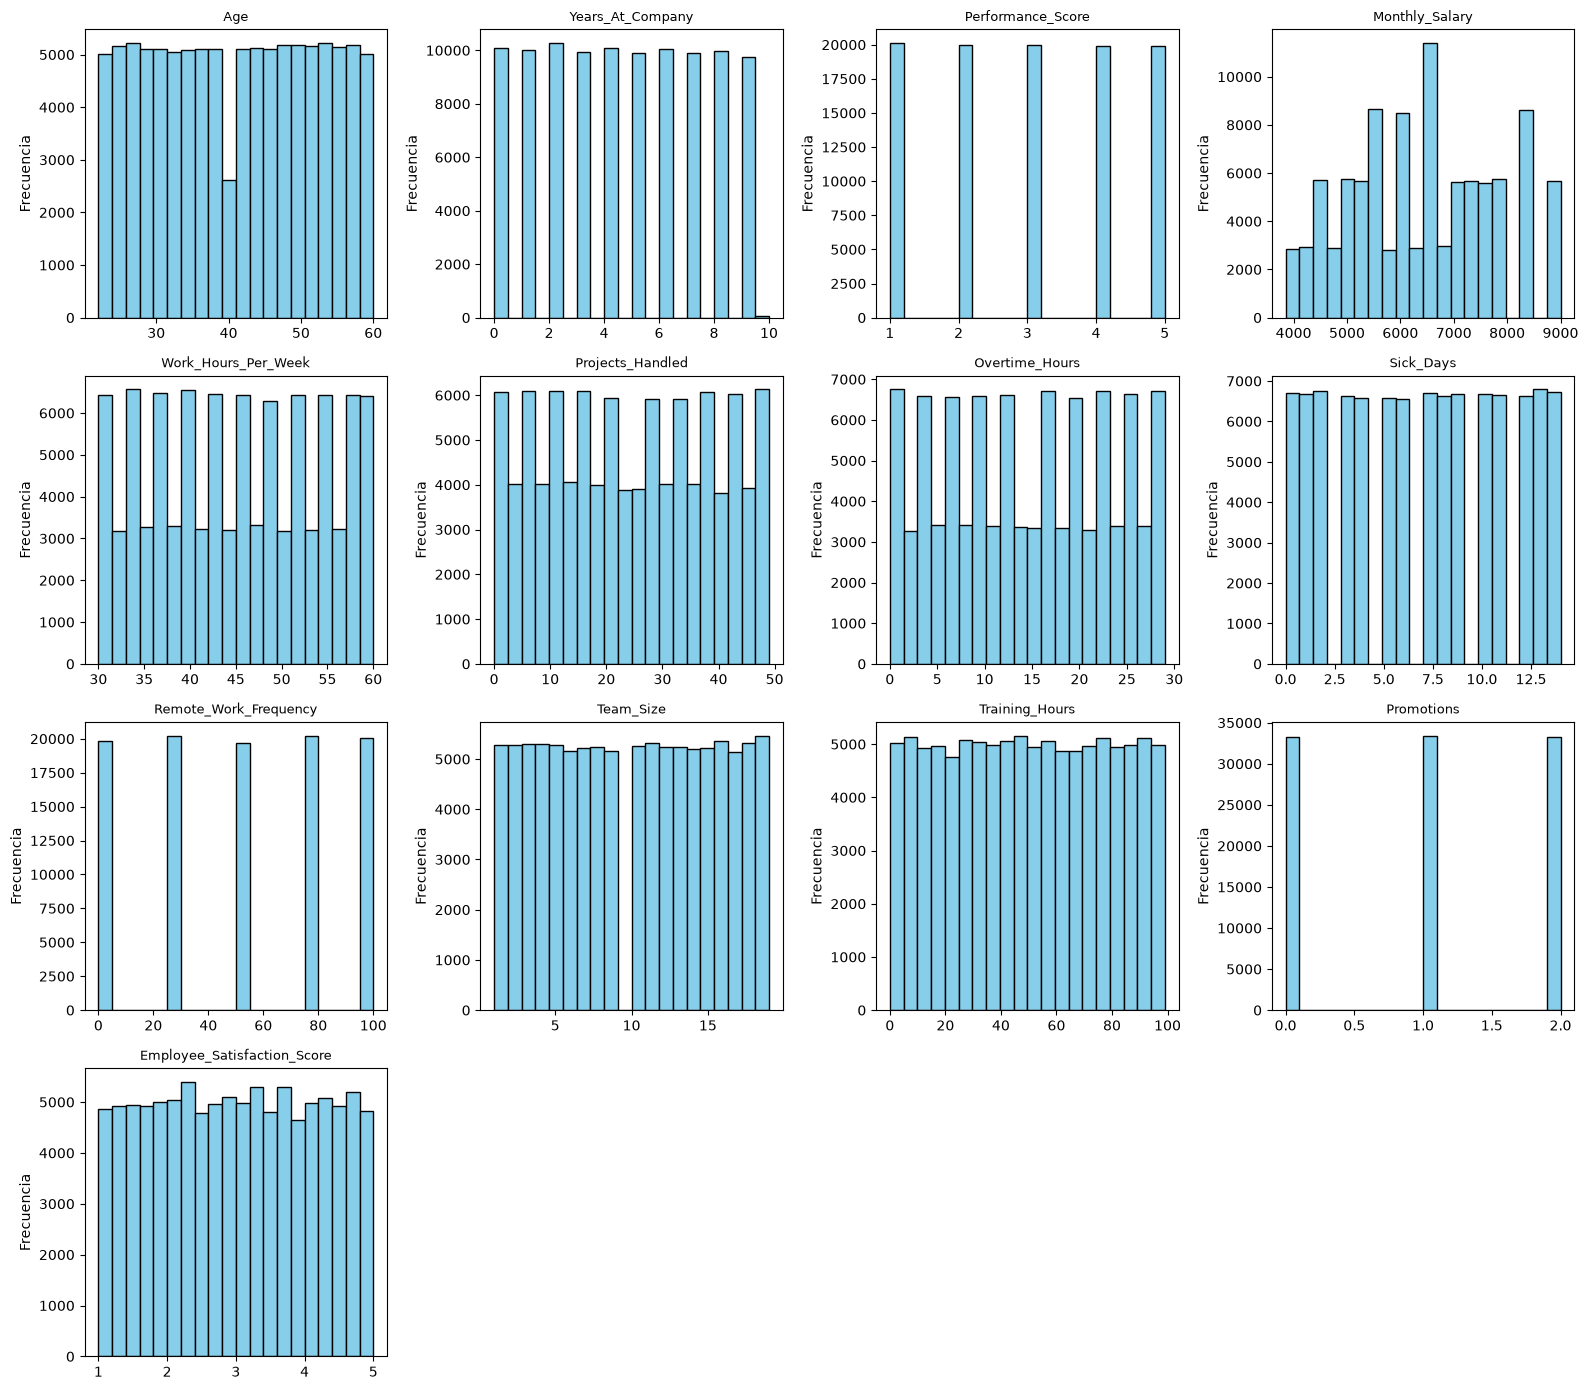

In [2]:
# Filtrar las columnas numéricas
numeric_columns = df.select_dtypes(include=['number']).drop('Employee_ID', axis=1)
cols = list(numeric_columns)
fig, axes = plt.subplots(4, 4, figsize=(16, 14))
for ax, col in zip(axes.flat, cols):
    ax.hist(df[col], bins=20, color='skyblue', edgecolor='black')
    ax.set_title(col, fontsize=9)
    ax.set_ylabel('Frecuencia')
for ax in list(axes.flat)[len(cols):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

**Problemas**, tenemos distribuciones con picos, esos nos indica categorías. Por otro lado, tenemos variables con "valles" en su distribución (distribuciones multimodales) por lo que resultaría óptimo aplicar técnicas de feature engeneering. Por último tenemos distribuciones uniformes, por lo que cada una requeriría un procesamiento indivudual, hagamos la vista gorda e intentemos ajustar un MLP con estos datos, solo estandaricemos nuestros datos.

---

## Implementación de Red:

To**memos los datos numéricos como nuestra variable X, y la variable objetivo como ***'Employee_Satisfaction_Score'***.
- **Actividad 1**: Para todos los strings marcados como pendientes que aparescan en el siguiente bloque de código cámbialos para que el código funcione.

In [3]:
X = numeric_columns.drop('Employee_Satisfaction_Score', axis=1)
y = numeric_columns['Employee_Satisfaction_Score']
y = y.apply(lambda x: round(x)-1)  # Cinco categorías: índices de 0 a 4
assert y.between(0, 4).all() and not X.isna().any().any()

# Reservar prueba antes de ajustar el escalador; validación es 20% del entrenamiento.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
X_fit_raw, X_val_raw, y_fit, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.20, random_state=42)
scaler = StandardScaler()
X_fit = scaler.fit_transform(X_fit_raw).astype('float32')
X_val = scaler.transform(X_val_raw).astype('float32')
X_train = scaler.transform(X_train_raw).astype('float32')
X_test = scaler.transform(X_test_raw).astype('float32')
y_onehot_train = tf.keras.utils.to_categorical(y_train, 5)
y_onehot_test = tf.keras.utils.to_categorical(y_test, 5)
y_onehot_fit = tf.keras.utils.to_categorical(y_fit, 5)
y_onehot_val = tf.keras.utils.to_categorical(y_val, 5)
print('Entrenamiento:', X_fit.shape, 'Validación:', X_val.shape, 'Prueba:', X_test.shape)
display(y.value_counts().sort_index().rename('Cantidad por categoría (0 a 4)').to_frame())
print('No se usa la satisfacción ni Employee_ID como predictores.')

Entrenamiento: (53600, 12) Validación: (13400, 12) Prueba: (33000, 12)


,Cantidad por categoría (0 a 4)
Employee_Satisfaction_Score,
0,12265
1,25326
2,24926
3,25311
4,12172


No se usa la satisfacción ni Employee_ID como predictores.


- **Actividad 2:** Implementa 3 arquitecturas de MLP, cada una con su propio nombre, cambiando la estructura de dichas arquitecturas (capas, neuronas por capa, función de activación, etc). 

In [4]:
# Tres arquitecturas distintas; misma entrada y salida.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
modelos = {
    'MLP_Simple': models.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(32, activation='relu'), layers.Dense(16, activation='relu'),
        layers.Dense(5, activation='softmax')], name='MLP_Simple'),
    'MLP_Profundo': models.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation='relu'), layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'), layers.Dense(5, activation='softmax')], name='MLP_Profundo'),
    'MLP_Regularizado': models.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(64, activation='relu'), layers.Dropout(0.3),
        layers.Dense(32, activation='relu'), layers.Dropout(0.3),
        layers.Dense(5, activation='softmax')], name='MLP_Regularizado')
}
for modelo in modelos.values():
    modelo.summary()

Model: "MLP_Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │            85 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,029 (4.02 KB)

 Trainable params: 1,029 (4.02 KB)

 Non-trainable params: 0 (0.00 B)

...

Model: "MLP_Regularizado"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,077 (12.02 KB)

 Trainable params: 3,077 (12.02 KB)

 Non-trainable params: 0 (0.00 B)

- **Actividad 3:** Compila y ajusta tus tres modelos con sus respectivos hiperparámetros.

Epoch 1/40


210/210 - 4s - 18ms/step - accuracy: 0.2419 - loss: 1.5873 - val_accuracy: 0.2528 - val_loss: 1.5639


Epoch 2/40


210/210 - 1s - 5ms/step - accuracy: 0.2541 - loss: 1.5604 - val_accuracy: 0.2559 - val_loss: 1.5600


Epoch 3/40


...

Epoch 14/40


210/210 - 1s - 5ms/step - accuracy: 0.2574 - loss: 1.5541 - val_accuracy: 0.2569 - val_loss: 1.5560


Epoch 15/40


210/210 - 1s - 5ms/step - accuracy: 0.2621 - loss: 1.5542 - val_accuracy: 0.2545 - val_loss: 1.5561


,Modelo,Test Accuracy,Test Loss,Mejor Val Accuracy,Épocas,Train Accuracy restaurada,Val Accuracy restaurada,Val Loss restaurada,Parámetros
0,MLP_Simple,0.253606,1.559970,0.255896,11,0.265261,0.254701,1.558113,1029
1,MLP_Profundo,0.251727,1.559852,0.258060,7,0.274179,0.253582,1.558785,12165
2,MLP_Regularizado,0.253121,1.557055,0.258582,15,0.263974,0.254925,1.555917,3077


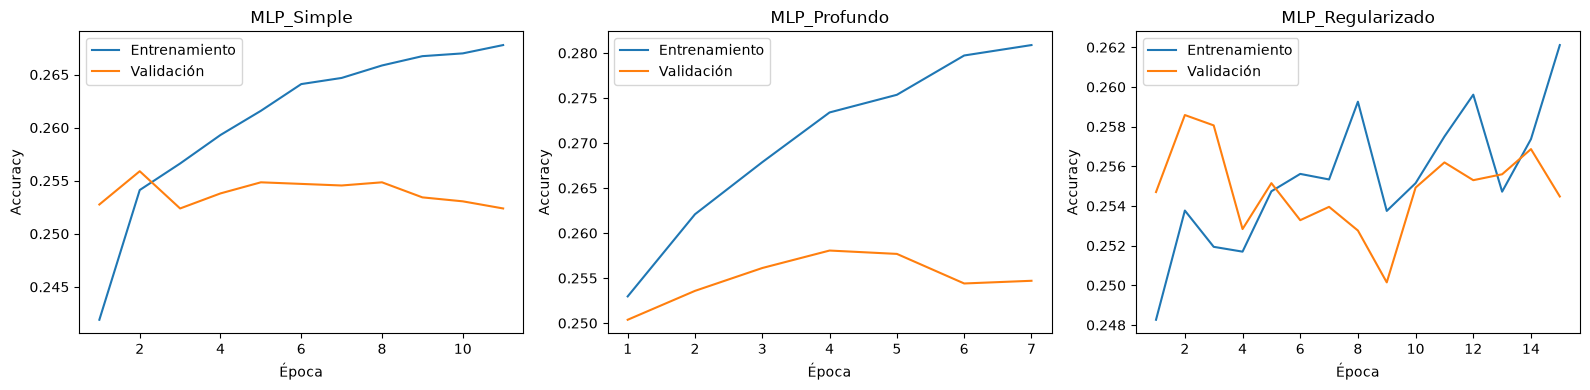

Baseline de clase mayoritaria en prueba: 25.3030%
Modelo seleccionado: MLP_Simple
MLP_Simple: brecha entrenamiento-validación = 1.0560%; loss final entrenamiento/validación = 1.5525/1.5583
MLP_Profundo: brecha entrenamiento-validación = 2.0597%; loss final entrenamiento/validación = 1.5469/1.5615
MLP_Regularizado: brecha entrenamiento-validación = 0.9049%; loss final entrenamiento/validación = 1.5542/1.5561


In [5]:
historiales = {}
filas = []
for nombre, modelo in modelos.items():
    tf.keras.utils.set_random_seed(42)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                   loss='categorical_crossentropy', metrics=['accuracy'])
    parada = tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=5, min_delta=0.0001, restore_best_weights=True)
    historial = modelo.fit(X_fit, y_onehot_fit, validation_data=(X_val, y_onehot_val),
                           epochs=40, batch_size=256, callbacks=[parada], verbose=2)
    historiales[nombre] = historial.history
    test_loss, test_accuracy = modelo.evaluate(X_test, y_onehot_test, verbose=0)
    train_loss, train_accuracy = modelo.evaluate(X_fit, y_onehot_fit, verbose=0)
    val_loss, val_accuracy = modelo.evaluate(X_val, y_onehot_val, verbose=0)
    filas.append({'Modelo': nombre, 'Test Accuracy': test_accuracy, 'Test Loss': test_loss,
                  'Mejor Val Accuracy': max(historial.history['val_accuracy']),
                  'Épocas': len(historial.history['loss']),
                  'Train Accuracy restaurada': train_accuracy, 'Val Accuracy restaurada': val_accuracy,
                  'Val Loss restaurada': val_loss, 'Parámetros': modelo.count_params()})
comparacion = pd.DataFrame(filas)
display(comparacion.round(6))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (nombre, historia) in zip(axes, historiales.items()):
    epocas = range(1, len(historia['accuracy']) + 1)
    ax.plot(epocas, historia['accuracy'], label='Entrenamiento')
    ax.plot(epocas, historia['val_accuracy'], label='Validación')
    ax.set(title=nombre, xlabel='Época', ylabel='Accuracy')
    ax.legend()
plt.tight_layout()
plt.show()

# Referencia sencilla: siempre predecir la clase más frecuente del entrenamiento.
clase_base = int(y_fit.mode().iloc[0])
baseline = float((y_test == clase_base).mean())
print(f'Baseline de clase mayoritaria en prueba: {baseline:.4%}')
# Selección por validación: prueba se usa solo para informar el desempeño final.
# Diferencias menores de 0.5 puntos porcentuales se consideran cercanas;
# entre esos candidatos se prefiere menor complejidad para esta práctica.
mejor_val = comparacion['Val Accuracy restaurada'].max()
candidatos = comparacion[comparacion['Val Accuracy restaurada'] >= mejor_val - 0.005]
elegido = candidatos.sort_values(['Parámetros', 'Val Loss restaurada']).iloc[0]
nombre_elegido = elegido['Modelo']
print('Modelo seleccionado:', nombre_elegido)
for fila in filas:
    brecha = fila['Train Accuracy restaurada'] - fila['Val Accuracy restaurada']
    h = historiales[fila['Modelo']]
    print(f"{fila['Modelo']}: brecha entrenamiento-validación = {brecha:.4%}; "
          f"loss final entrenamiento/validación = {h['loss'][-1]:.4f}/{h['val_loss'][-1]:.4f}")

- **Actividad 4:** Sube tus cambios al repositorio, envía el link de tu repositorio a la actividad 2 de tu checkpoint 2 y contesta las preguntas de dicha actividad.

## Comparación y selección del modelo

Los tres modelos usan los mismos datos, Adam (0.001), lotes de 256 y hasta 40 épocas con EarlyStopping por pérdida de validación. Se restauran los pesos con menor pérdida de validación; por ello la mejor accuracy de validación del historial puede corresponder a otra época. La evaluación final usa exactamente `X_test` y `y_onehot_test`.

La selección se basa en validación y complejidad, considerando cercanas las accuracies que difieren hasta 0.5 puntos porcentuales. La prueba sirve para comprobar el desempeño final; elegir repetidamente por prueba podría sobreajustar la decisión a ese conjunto. La siguiente conclusión se calcula con la ejecución real.

In [6]:
brecha = elegido['Train Accuracy restaurada'] - elegido['Val Accuracy restaurada']
display(Markdown(
    f"Elijo **{nombre_elegido}**, con **{elegido['Test Accuracy']:.2%}** de accuracy "
    f"y **{elegido['Test Loss']:.4f}** de pérdida en prueba. Su mejor accuracy de validación "
    f"fue **{elegido['Mejor Val Accuracy']:.2%}**, y entrenó **{int(elegido['Épocas'])} épocas**. "
    f"Tiene **{int(elegido['Parámetros']):,} parámetros**, y es el menos complejo entre los "
    f"candidatos cercanos al mejor resultado de validación. La brecha entre entrenamiento "
    f"y validación de sus pesos restaurados es **{brecha:.2%}**. "
    f"La referencia de clase mayoritaria obtiene **{baseline:.2%}** en prueba. "
    "Una accuracy cercana a esta referencia indica capacidad predictiva limitada y no permite "
    "afirmar que el modelo sea útil para decisiones de recursos humanos."
))
for nombre, h in historiales.items():
    aumento = h['val_loss'][-1] - min(h['val_loss'])
    texto = ('Hay indicios leves de sobreajuste al final: la pérdida de validación aumenta '
             'respecto a su mínimo; EarlyStopping restaura los mejores pesos.'
             if aumento > 0.001 and h['loss'][-1] < h['loss'][0] else
             'No se observa un aumento grande de pérdida de validación respecto a su mínimo; '
             'esto por sí solo no demuestra buena generalización.')
    display(Markdown(f'**{nombre}:** {texto}'))

Elijo **MLP_Simple**, con **25.36%** de accuracy y **1.5600** de pérdida en prueba. Su mejor accuracy de validación fue **25.59%**, y entrenó **11 épocas**. Tiene **1,029 parámetros**, y es el menos complejo entre los candidatos cercanos al mejor resultado de validación. La brecha entre entrenamiento y validación de sus pesos restaurados es **1.06%**. La referencia de clase mayoritaria obtiene **25.30%** en prueba. Una accuracy cercana a esta referencia indica capacidad predictiva limitada y no permite afirmar que el modelo sea útil para decisiones de recursos humanos.

**MLP_Simple:** No se observa un aumento grande de pérdida de validación respecto a su mínimo; esto por sí solo no demuestra buena generalización.

**MLP_Profundo:** Hay indicios leves de sobreajuste al final: la pérdida de validación aumenta respecto a su mínimo; EarlyStopping restaura los mejores pesos.

**MLP_Regularizado:** No se observa un aumento grande de pérdida de validación respecto a su mínimo; esto por sí solo no demuestra buena generalización.

## Respuestas para el foro

Las respuestas siguientes insertan las métricas reales del modelo seleccionado.

In [7]:
display(Markdown(
    f"**1. ¿Con cuál de tus tres modelos te quedarías y por qué?**\n\n"
    f"Me quedaría con **{nombre_elegido}**. Obtuvo **{elegido['Test Accuracy']:.2%} de accuracy "
    f"en prueba**, una pérdida de **{elegido['Test Loss']:.4f}** y una mejor accuracy de "
    f"validación de **{elegido['Mejor Val Accuracy']:.2%}**. Su resultado de validación es "
    "cercano al mejor y requiere menos parámetros entre esos candidatos. No elegiría una red "
    "más profunda solo por tener más capas. Aun así, compararía este resultado con la referencia "
    f"mayoritaria ({baseline:.2%}), porque el desempeño sigue siendo limitado.\n\n"
    "**2. A pesar de decidir un modelo final, ¿considerarías mejoras a ese mismo? ¿Cuáles?**\n\n"
    "Sí. Primero revisaría si las variables disponibles ayudan a explicar la satisfacción e "
    "incorporaría variables categóricas como departamento y puesto mediante una codificación "
    "adecuada. También probaría pequeños cambios en neuronas y learning rate usando solo "
    "entrenamiento y validación, conservando EarlyStopping. Evaluaría precision, recall y matriz "
    "de confusión por clase, porque las categorías creadas al redondear no tienen el mismo tamaño. "
    "Antes de aumentar capas, comprobaría con varias particiones si las mejoras son consistentes."
))

**1. ¿Con cuál de tus tres modelos te quedarías y por qué?**

Me quedaría con **MLP_Simple**. Obtuvo **25.36% de accuracy en prueba**, una pérdida de **1.5600** y una mejor accuracy de validación de **25.59%**. Su resultado de validación es cercano al mejor y requiere menos parámetros entre esos candidatos. No elegiría una red más profunda solo por tener más capas. Aun así, compararía este resultado con la referencia mayoritaria (25.30%), porque el desempeño sigue siendo limitado.

**2. A pesar de decidir un modelo final, ¿considerarías mejoras a ese mismo? ¿Cuáles?**

Sí. Primero revisaría si las variables disponibles ayudan a explicar la satisfacción e incorporaría variables categóricas como departamento y puesto mediante una codificación adecuada. También probaría pequeños cambios en neuronas y learning rate usando solo entrenamiento y validación, conservando EarlyStopping. Evaluaría precision, recall y matriz de confusión por clase, porque las categorías creadas al redondear no tienen el mismo tamaño. Antes de aumentar capas, comprobaría con varias particiones si las mejoras son consistentes.

In [8]:
# Versiones y controles de integridad de la ejecución.
import hashlib, platform, sklearn, matplotlib
csv_hash = hashlib.sha256(open('Extended_Employee_Performance_and_Productivity_Data.csv', 'rb').read()).hexdigest()
assert csv_hash == '1004443324eded5c722effac4d98059b359d46a5b473aeed98793480fe92c76d'
assert len(historiales) == 3 and all(len(h['loss']) > 0 for h in historiales.values())
assert len(comparacion) == 3 and np.isfinite(comparacion.select_dtypes('number')).all().all()
print('CSV original sin cambios (SHA256):', csv_hash)
print('Python:', platform.python_version(), '| TensorFlow:', tf.__version__, '| NumPy:', np.__version__)
print('pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__, '| matplotlib:', matplotlib.__version__)
print('Verificación completada: tres modelos entrenados y métricas reales.')

CSV original sin cambios (SHA256): 1004443324eded5c722effac4d98059b359d46a5b473aeed98793480fe92c76d
Python: 3.12.14 | TensorFlow: 2.21.0 | NumPy: 2.5.4
pandas: 3.1.0 | scikit-learn: 1.9.1 | matplotlib: 3.11.2
Verificación completada: tres modelos entrenados y métricas reales.
